In [ ]:
# Setup: download the data (needed in Google Colab, skipped if the file already exists)
import os, urllib.request

BASE = "https://raw.githubusercontent.com/BRCCH-2026/BRCCH-2026/main/"
for f in ["heart_disease_data.csv"]:
    if not os.path.exists(f):
        urllib.request.urlretrieve(BASE + f, f)

# Classification pipeline

![Description](ML-pipeline.jpg)

[Image Source]: https://www.design-reuse.com/article/61411-an-overview-of-machine-learning-pipeline-and-its-importance/


1. **_Problem setup_**:  Define task, target, metrics (e.g., ROC-AUC, F1), constraints,
2. _**Wrangle and assess**_:  Exploratory Data Analysis for schema/types, ranges, outliers; fix types; standardize units; handle duplicates; document data quality issues
3. _**Feature engineering \& encoding**_
- Categorical encoding: one-hot, ordinal, target encoding, frequency encoding
- Numeric preprocessing : scale/normalize (StandardScaler, MinMaxScaler, RobustScaler)
- Domain features : ratios, interactions, polynomial features, binning
- Missing data: diagnose MCAR/MAR/MNAR, then delete or impute (mean/median, regression, kNN, multiple imputation)
- Feature selection: correlation filtering, univariate tests, recursive feature elimination (RFE), LASSO regularization, tree-based importance

1. _**Data splits \& cross-validation**_
- Initial split: stratified train/validation/test; ensure no leakage; fix seeds
- Cross-validation strategies:
    - k-fold CV for model selection and hyperparameter tuning
    - Stratified k-fold for imbalanced datasets
    - Time series split for temporal data
    - Group k-fold when data has natural groupings
- Nested CV: outer loop for final performance estimate, inner loop for hyperparameter optimization

1. **_Train and select with CV_**
- Cross-validation for robust model evaluation; regularization (L1/L2), early stopping
- Hyperparameter tuning: GridSearchCV, RandomizedSearchCV, or Bayesian optimization
- Feature selection within CV: use cross_val_score with feature selectors to avoid data leakage

1. _**Final evaluation and Deployment_**
- Single test on held-out set after all CV-based model selection
- Report metrics with confidence intervals from CV; document model limitations

## scikit-learn Classification Example with Heart Disease Dataset

This notebook demonstrates a full classification workflow on the heart disease dataset using **scikit-learn**, the most widely used machine learning library in Python.

We will train and compare two simple, easy-to-interpret models:
- **Logistic Regression**: learns one weight (coefficient) per feature and combines them into a probability.
- **K-Nearest Neighbors (KNN)**: predicts the label of a patient by looking at the *k* most similar patients in the training data.

In [1]:
# Install dependencies if needed (uncomment to run, but this will not be needed in copilot)
# !uv pip install -U scikit-learn pandas seaborn matplotlib joblib

In [2]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay,
                             accuracy_score, classification_report, f1_score,
                             make_scorer, precision_score, recall_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold,
                                     cross_validate, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

A typical workflow in scikit-learn consists of the following steps:

Split the data ➡️ Preprocess ➡️ Train models with cross-validation ➡️ Tune hyperparameters ➡️ Evaluate on the test set ➡️ Save the model

In scikit-learn every model has the same two main methods:
- `.fit(X, y)` to **train** the model on features `X` and target `y`
- `.predict(X)` to **predict** the target for new data

### 1. Get and Load the data correctly

We need to load the data in the correct data type with meaningul descriptions

| Column | Data Type | Description |
| :-- | :-- | :-- |
| age | int64 | Patient's age (years) |
| sex | category | Patient's sex (female/male) |
| cp | category | Chest pain type |
| trestbps | int64 | Resting blood pressure (mm Hg) |
| chol | int64 | Serum cholesterol (mg/dl) |
| fbs | category | Fasting blood sugar (<=120mg/dl / >120mg/dl) |
| restecg | category | Resting electrocardiographic results |
| thalach | int64 | Maximum heart rate achieved |
| exang | category | Exercise induced angina (no/yes) |
| oldpeak | float64 | ST depression induced by exercise |
| slope | category | Slope of peak exercise ST segment |
| ca | float64 | Number of major vessels (0-3) colored by fluoroscopy |
| thal | category | Thalassemia type |
| num | int64 | Heart disease diagnosis (target variable) |

In [3]:
# Load data
filepath = 'heart_disease_data.csv'
heart_data = pd.read_csv(filepath, index_col=0)

#Drop duplicate rows: 
print('Rows before:', len(heart_data))
heart_data = heart_data.drop_duplicates()
print('Rows after: ', len(heart_data))

# Convert categorical columns to category dtype
categorical_columns = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']
for col in categorical_columns:
    heart_data[col] = heart_data[col].astype('category')

# Add meaningful labels for some categorical variables
heart_data['sex'] = heart_data['sex'].cat.rename_categories({0: 'female', 1: 'male'})
heart_data['fbs'] = heart_data['fbs'].cat.rename_categories({0: '<=120mg/dl', 1: '>120mg/dl'})
heart_data['exang'] = heart_data['exang'].cat.rename_categories({0: 'no', 1: 'yes'})
heart_data.loc[heart_data.num>=1,'num'] = 1 #Replace all the <=1 categories with a positive heart disease diagnosis

# Display the first few rows
heart_data.head()


Rows before: 303
Rows after:  303


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,male,1,145,233,>120mg/dl,2,150,no,2.3,3,0.0,6.0,0
1,67,male,4,160,286,<=120mg/dl,2,108,yes,1.5,2,3.0,3.0,1
2,67,male,4,120,229,<=120mg/dl,2,129,yes,2.6,2,2.0,7.0,1
3,37,male,3,130,250,<=120mg/dl,0,187,no,3.5,3,0.0,3.0,0
4,41,female,2,130,204,<=120mg/dl,2,172,no,1.4,1,0.0,3.0,0


#### 1.b Create The binarized outcome

We need to define our target column and/or binarize it. Some data exploration to understand if there is an imbalance

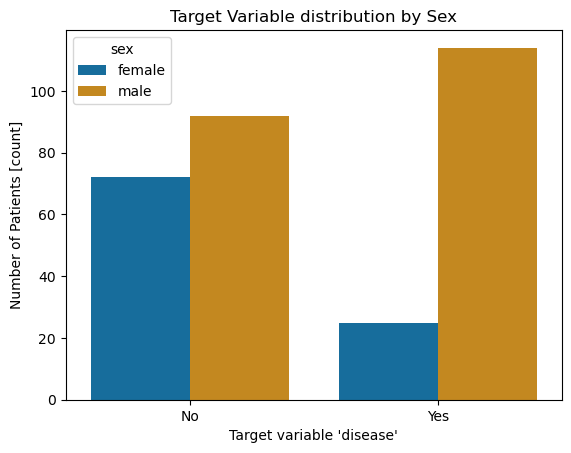

In [4]:
# Create the Heart Failure variable derived form  diagnosis of heart disease

# Create the binary target
heart_data['disease'] = heart_data['num'].map({0: 'No', 1: 'Yes'})

# Remove the original column to avoid data leakage
heart_data.drop('num', axis=1, inplace=True)

# Keep only rows with labels No or Yes to avoid missing labels
heart_data = heart_data[heart_data['disease'].isin(['No','Yes'])].copy()
# Plot to check the label distribution

fig = sns.countplot(x = 'disease', data = heart_data, palette = "colorblind",hue= "sex")
             # title=f'Target Label 'disease' Distribution')
fig.set(
    xlabel="Target variable \'disease\'",
    ylabel="Number of Patients [count]",
    title= "Target Variable distribution by Sex"
)

plt.show()


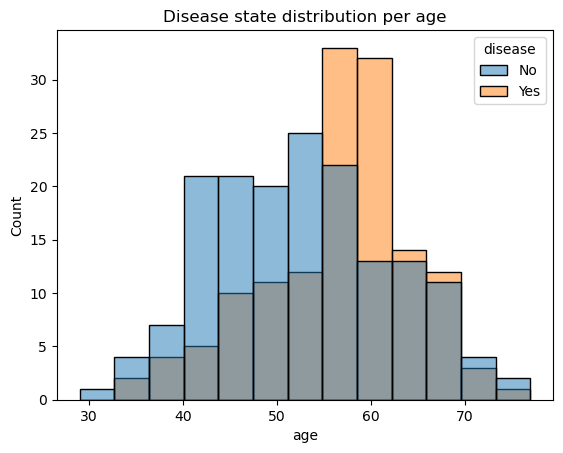

In [5]:
sns.histplot(data=heart_data, x='age', hue='disease')
plt.title('Disease state distribution per age')
plt.show()

### 2. Split the data into train and test sets

First, we separate the **features** (`X`, the information we use to predict) from the **target** (`y`, what we want to predict).

Then we split the data:
- **Training set (80%)**: used to train and tune the models
- **Test set (20%)**: kept aside and only used *once* at the end to check how well the final model works on unseen patients

`stratify=y` makes sure both sets have the same proportion of 'Yes' and 'No'. `random_state=42` fixes the random seed so we get the same split every time we run the notebook.

In [6]:
# Features (X) and target (y)
X = heart_data.drop('disease', axis=1)
y = heart_data['disease']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,     # 20% of the data goes to the test set
    stratify=y,        # keep the same Disease/Healthy proportion per split
    random_state=42,   # seed for reproducibility
)

print('Training set shape:', X_train.shape)
print('Test set shape:    ', X_test.shape)

Training set shape: (242, 13)
Test set shape:     (61, 13)


### 3. Set up the preprocessing

Machine learning models only understand numbers, and most of them cannot handle missing values. So before training we need to:

- **Numeric features**: fill missing values with the mean (`SimpleImputer`) and put all features on the same scale (`StandardScaler`). Scaling is very important for KNN (it uses distances between patients) and for Logistic Regression.
- **Categorical features**: fill missing values with the most frequent value and convert each category into 0/1 columns (`OneHotEncoder`).

A `ColumnTransformer` applies the right steps to the right columns.

In [7]:
numeric_columns = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']
# categorical_columns was defined when we loaded the data

# Steps for numeric columns
numeric_preprocessing = Pipeline(steps=[ #Pipeline is a function that helps create a reproducible workflow of steps
    ('imputer', SimpleImputer(strategy='mean')), #Other choices: median, most_frequent, constant (depends on the task)
    ('scaler', StandardScaler()),
])

# Steps for categorical columns
categorical_preprocessing = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])

# Apply each set of steps to the right columns
preprocessing = ColumnTransformer(transformers=[
    ('numeric', numeric_preprocessing, numeric_columns),
    ('categorical', categorical_preprocessing, categorical_columns),
])

preprocessing

ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('imputer', SimpleImputer()),
                                                 ('scaler', StandardScaler())]),
                                 ['age', 'trestbps', 'chol', 'thalach',
                                  'oldpeak', 'ca']),
                                ('categorical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['sex', 'cp', 'fbs', 'restecg', 'exang',
                                  'slope', 'thal'])])

### 4. Create the models

We combine the preprocessing and the model into a single **Pipeline**. This has two big advantages:
- We can call `.fit()` and `.predict()` on the whole thing, just like a single model.
- The preprocessing is learned **only on the training data**, which avoids data leakage.

In [8]:
# Model 1: Logistic Regression
logreg_pipeline = Pipeline(steps=[
    ('preprocessing', preprocessing),
    ('model', LogisticRegression(max_iter=1000, random_state=42)),
])

# Model 2: K-Nearest Neighbors
knn_pipeline = Pipeline(steps=[
    ('preprocessing', preprocessing),
    ('model', KNeighborsClassifier(n_neighbors=5)),
])

#Model 3: you choose! Some options are Ridge Classifier
rc_pipeline = Pipeline(steps=[
    ('preprocessing', preprocessing),
    ('model', RidgeClassifier(random_state=42))
])

logreg_pipeline

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak',
                                                   'ca']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['sex', 'cp', 'fbs',
                                                   'restecg', 'exang', 'slope',
                                                   'thal'])])),
                ('model', LogisticRegression(max_iter=1000, random_state=42))])

### 5. Compare the models with cross-validation

To compare the models fairly, we use **10-fold stratified cross-validation** on the training set: the training data is split into 10 parts, the model is trained on 9 parts and evaluated on the remaining part, and this is repeated 10 times. We then look at the average score.

We compute several metrics:
- **Accuracy**: fraction of correct predictions
- **ROC-AUC**: how well the model separates 'Yes' from 'No' (1 = perfect, 0.5 = random guessing)
- **Recall**: fraction of real 'Yes' patients that the model finds
- **Precision**: fraction of predicted 'Yes' patients that really are 'Yes'
- **F1**: a balance between recall and precision

In [9]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# Tell scikit-learn that 'Yes' is the positive class for recall/precision/F1
scoring = {
    'accuracy': 'accuracy',
    'roc_auc': 'roc_auc',
    'recall': make_scorer(recall_score, pos_label='Yes'),
    'precision': make_scorer(precision_score, pos_label='Yes'),
    'f1': make_scorer(f1_score, pos_label='Yes'),
}

models = {
    'Logistic Regression': logreg_pipeline,
    'KNN': knn_pipeline,
    'Ridge Classifier': rc_pipeline
}

results = {}
for name, pipeline in models.items():
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring)
    results[name] = {metric: scores[f'test_{metric}'].mean() for metric in scoring}

results_df = pd.DataFrame(results).T.round(3)
results_df

,accuracy,roc_auc,recall,precision,f1
Logistic Regression,0.831,0.907,0.776,0.856,0.807
KNN,0.823,0.868,0.802,0.817,0.803
Ridge Classifier,0.818,0.898,0.748,0.860,0.789


### 6. Tune the model hyperparameters

Until now we used the **default hyperparameters** (settings chosen before training). We can often do better by trying several values and keeping the best one. `GridSearchCV` tries every combination in a grid, using cross-validation for each one.

- **Logistic Regression** – `C`: controls the regularization. Smaller `C` value = simpler model that is less likely to overfit, larger `C` value = more complex/flexible model, may overfit.
- **KNN** – `n_neighbors`: how many neighbours to consider. `weights`: 'uniform' gives every neighbour an equal vote, `distance` gives closer neighbours a bigger vote.
- 
Note: to set a parameter of a step inside a pipeline we write `<step name>_<parameter>`, e.g. `model_C`.

In [10]:
# Optimize Logistic Regression
logreg_grid = {
    'model__C': [0.001, 0.01, 0.1, 1, 10, 100],
}
logreg_search = GridSearchCV(logreg_pipeline, logreg_grid, cv=cv, scoring='roc_auc')
logreg_search.fit(X_train, y_train)

print('Best parameters:', logreg_search.best_params_)
print('Best CV ROC-AUC:', round(logreg_search.best_score_, 3))

Best parameters: {'model__C': 1}
Best CV ROC-AUC: 0.907


In [11]:
# Optimize KNN
knn_grid = {
    'model__n_neighbors': [3, 5, 7, 9, 11, 15, 21],
    'model__weights': ['uniform', 'distance'],
}
knn_search = GridSearchCV(knn_pipeline, knn_grid, cv=cv, scoring='roc_auc')
knn_search.fit(X_train, y_train)

print('Best parameters:', knn_search.best_params_)
print('Best CV ROC-AUC:', round(knn_search.best_score_, 3))

Best parameters: {'model__n_neighbors': 15, 'model__weights': 'distance'}
Best CV ROC-AUC: 0.893


In [12]:
# Optimize other model
rc_grid = {
    'model__alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

rc_search = GridSearchCV(rc_pipeline, rc_grid, cv=cv, scoring='roc_auc')
rc_search.fit(X_train, y_train)

print('Best parameters:', rc_search.best_params_)
print('Best CV ROC-AUC:', round(rc_search.best_score_, 3))

Best parameters: {'model__alpha': 100}
Best CV ROC-AUC: 0.913


`GridSearchCV` also stores the results of every combination it tried in `cv_results_`. We can turn it into a DataFrame to look at it. Here we plot how the KNN score changes with the number of neighbours.

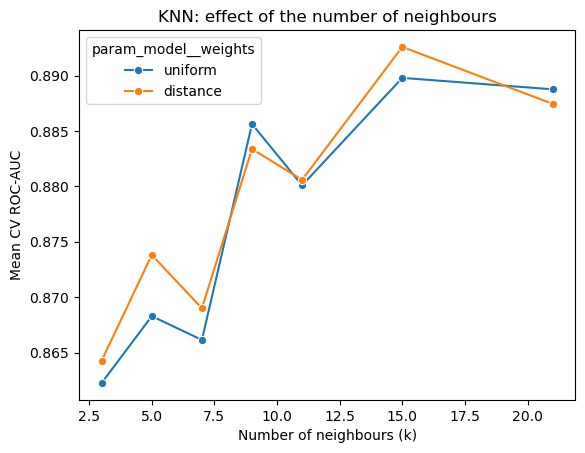

In [13]:
knn_results = pd.DataFrame(knn_search.cv_results_)

fig = sns.lineplot(data=knn_results, x='param_model__n_neighbors', y='mean_test_score',
                   hue='param_model__weights', marker='o')
fig.set(
    xlabel='Number of neighbours (k)',
    ylabel='Mean CV ROC-AUC',
    title='KNN: effect of the number of neighbours',
)
plt.show()

In [14]:
# Keep the best (tuned) version of each model
tuned_logreg = logreg_search.best_estimator_
tuned_knn = knn_search.best_estimator_
tuned_rc = rc_search.best_estimator_

### 7. Evaluate the models on the test set

Now that we have chosen our models, we evaluate them **once** on the test set that we kept aside. This tells us how well the models work on patients they have never seen.

In [15]:
tuned_models = {
    'Logistic Regression': tuned_logreg,
    'KNN': tuned_knn,
    'Ridge Classifier': tuned_rc
}

for name, model in tuned_models.items():
    y_pred = model.predict(X_test)
    print(f'===== {name} =====')
    print(classification_report(y_test, y_pred))

===== Logistic Regression =====
              precision    recall  f1-score   support

          No       0.93      0.82      0.87        33
         Yes       0.81      0.93      0.87        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.88      0.87      0.87        61

===== KNN =====
              precision    recall  f1-score   support

          No       0.88      0.85      0.86        33
         Yes       0.83      0.86      0.84        28

    accuracy                           0.85        61
   macro avg       0.85      0.85      0.85        61
weighted avg       0.85      0.85      0.85        61

===== Ridge Classifier =====
              precision    recall  f1-score   support

          No       0.93      0.85      0.89        33
         Yes       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        

#### Confusion matrix
The confusion matrix shows how many patients were correctly and incorrectly classified for each class.

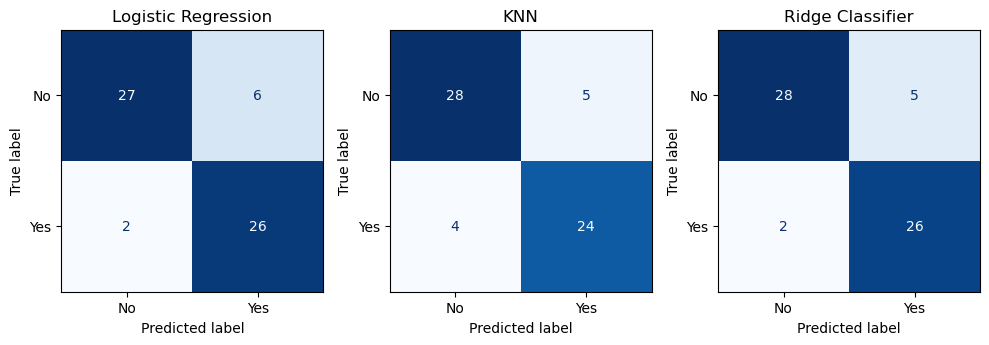

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(10, 4))

for ax, (name, model) in zip(axes, tuned_models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)

plt.tight_layout()

# to save the plot to PNG
results_dir = Path('results_best_model')
results_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(results_dir / 'confusion_matrix.png', dpi=150)

plt.show()

#### ROC curve
The ROC curve shows the trade-off between finding the sick patients (true positive rate) and raising false alarms (false positive rate). The closer the curve is to the top-left corner, the better. The dashed line is a model that guesses randomly.

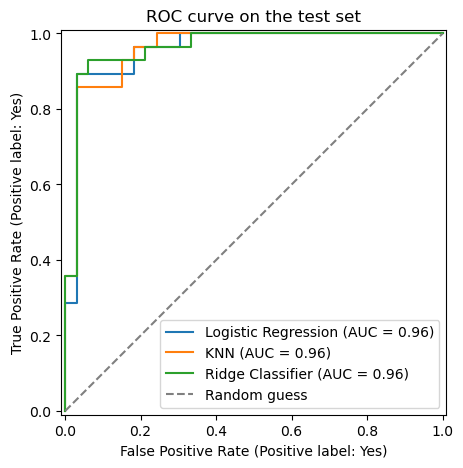

In [17]:
fig, ax = plt.subplots(figsize=(6, 5))

for name, model in tuned_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)

ax.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Random guess')
ax.set_title('ROC curve on the test set')
ax.legend()
plt.show()

#### Which features are important?
A nice property of Logistic Regression is that it is easy to interpret: each feature gets a **coefficient**.
- A **positive** coefficient increases the probability of 'Yes' (heart failure)
- A **negative** coefficient decreases it
- The larger the value (in absolute terms), the more important the feature

Because we scaled the numeric features, we can compare the coefficients with each other.

KNN does not learn coefficients, so this plot is only available for Logistic Regression.

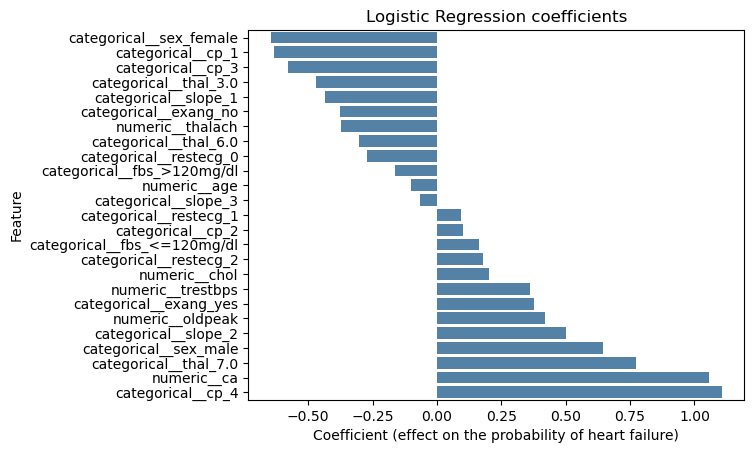

In [25]:
# Names of the features after preprocessing (one-hot encoding creates new columns)
feature_names = tuned_logreg.named_steps['preprocessing'].get_feature_names_out()
coefficients = tuned_logreg.named_steps['model'].coef_[0]

coef_df = pd.DataFrame({'feature': feature_names, 'coefficient': coefficients})
coef_df = coef_df.sort_values('coefficient')

fig = sns.barplot(data=coef_df, x='coefficient', y='feature', color='steelblue')
fig.set(
    xlabel='Coefficient (effect on the probability of heart failure)',
    ylabel='Feature',
    title='Logistic Regression coefficients',
)
plt.show()

#### Check Fairness
There are many approaches to conceptualizing fairness. Here we use a simple version of **group fairness**, which asks: does the model perform equally well for different groups of patients (also called sub-populations)?

We compare the accuracy and recall of each model for female and male patients in the test set. A large difference between groups is a warning sign.

In [19]:
fairness_rows = []
for name, model in tuned_models.items():
    y_pred = pd.Series(model.predict(X_test), index=X_test.index)
    for group in X_test['sex'].cat.categories:
        in_group = X_test['sex'] == group
        fairness_rows.append({
            'model': name,
            'sex': group,
            'n_patients': in_group.sum(),
            'accuracy': accuracy_score(y_test[in_group], y_pred[in_group]),
            'recall': recall_score(y_test[in_group], y_pred[in_group], pos_label='Yes'),
        })

fairness_df = pd.DataFrame(fairness_rows).round(3)
fairness_df

,model,sex,n_patients,accuracy,recall
0,Logistic Regression,female,20,0.950,0.857
1,Logistic Regression,male,41,0.829,0.952
2,KNN,female,20,0.950,0.857
3,KNN,male,41,0.805,0.857
4,Ridge Classifier,female,20,0.950,0.857
5,Ridge Classifier,male,41,0.854,0.952


### 8. Predict with the model
The `predict` method returns the predicted label and `predict_proba` returns the probability of each class in the Logistic Regression model. Here we add both as new columns to the test set so we can compare them with the real labels.

In [27]:
predictions = X_test.copy()
predictions['heart_disease'] = y_test
predictions['prediction_label'] = tuned_logreg.predict(X_test)

# predict_proba returns one column per class; tuned_logreg.classes_ tells us the order (['No', 'Yes'])
predictions['prediction_score_Yes'] = tuned_logreg.predict_proba(X_test)[:, 1].round(3)

predictions.head(10)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,heart_disease,prediction_label,prediction_score_Yes
219,59,male,4,138,271,<=120mg/dl,2,182,no,0.0,1,0.0,3.0,No,No,0.210
271,66,male,4,160,228,<=120mg/dl,2,138,no,2.3,1,0.0,6.0,No,Yes,0.646
89,51,female,3,130,256,<=120mg/dl,2,149,no,0.5,1,0.0,3.0,No,No,0.024
101,34,male,1,118,182,<=120mg/dl,2,174,no,0.0,1,0.0,3.0,No,No,0.032
67,54,male,3,150,232,<=120mg/dl,2,165,no,1.6,1,0.0,7.0,No,No,0.320
244,60,female,3,120,178,>120mg/dl,0,96,no,0.0,1,0.0,3.0,No,No,0.012
185,63,female,2,140,195,<=120mg/dl,0,179,no,0.0,1,2.0,3.0,No,No,0.115
233,74,female,2,120,269,<=120mg/dl,2,121,yes,0.2,1,1.0,3.0,No,No,0.230
168,35,male,4,126,282,<=120mg/dl,2,156,yes,0.0,1,0.0,7.0,Yes,Yes,0.762
197,45,female,4,138,236,<=120mg/dl,2,152,yes,0.2,2,0.0,3.0,No,No,0.416


### 9. Finalize and Save the model for 'Deployment'
Finalizing the model is the last step of the experiment. We choose the best model (based on the cross-validation results) and train it again on the **complete data set**, including the test set. The idea is to use all the available data before the model is deployed into production.

We save the model to a file with `joblib`, so it can be loaded later without training it again.

DISCLAIMER: Evaluating the final model on the test set is not conceptually correct anymore, as the final model has now also been trained on the test set.

0.9126373626373626

In [34]:
highest_score = max(logreg_search.best_score_,knn_search.best_score_,rc_search.best_score_)

# Choose the model with the best cross-validation ROC-AUC
if logreg_search.best_score_ == highest_score:
    best_name, final_model = 'Logistic Regression', tuned_logreg
if knn_search.best_score_ == highest_score:
    best_name, final_model = 'KNN', tuned_knn
else:
    best_name, final_model = 'Ridge Regression', tuned_rc

print('Best model:', best_name)

# Retrain on all the data (train + test)
final_model.fit(X, y)

# Create a directory to save the model
Path('models').mkdir(parents=True, exist_ok=True)
# Save the model
joblib.dump(final_model, 'models/heart_disease_model.pkl')

Best model: Ridge Regression


['models/heart_disease_model.pkl']

### 10. Load Model and infer
To use the saved model at a later date, in the same or in another environment, we load it with `joblib.load()` and then apply it to new, unseen data with `predict()`.

Important: the new data must have the **same columns and data types** as the data used for training (so it needs the same loading and cleaning steps as in section 1).

In [36]:
# Load the new completely unseen data
# data_unseen = pd.read_csv('PathNewData.csv', index_col=0)
# For this demo, we take 5 patients from our dataset (without the target column)
data_unseen = X.sample(5, random_state=1)

# Load the trained final model
saved_final_model = joblib.load('models/heart_disease_model.pkl')

# Predict the outcome with the labels
new_prediction = data_unseen.copy()
new_prediction['prediction_label'] = saved_final_model.predict(data_unseen)
#new_prediction['prediction_score_Yes'] = saved_final_model.predict_proba(data_unseen)[:, 1].round(3)
new_prediction

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,prediction_label
204,43,male,4,110,211,<=120mg/dl,0,161,no,0.0,1,0.0,7.0,No
159,68,male,3,118,277,<=120mg/dl,0,151,no,1.0,1,1.0,7.0,No
219,59,male,4,138,271,<=120mg/dl,2,182,no,0.0,1,0.0,3.0,No
174,64,male,4,145,212,<=120mg/dl,2,132,no,2.0,2,2.0,6.0,Yes
184,60,female,4,158,305,<=120mg/dl,2,161,no,0.0,1,0.0,3.0,No
